# MedAgent: 03. Photoplethysmography (PPG) Signal Analysis
## Continuous Optical Pulse Wave Processing & Pulse Rate Variability (PRV)

This notebook implements physiological signal analysis for Photoplethysmography (PPG):
1. Principles of optical blood volume pulse monitoring.
2. Filtering PPG signals ($0.5 - 8.0\text{ Hz}$ bandpass) to isolate pulsatile cardiac components.
3. Systolic peak detection & Pulse-to-Pulse Interval (PPI) extraction.
4. Time-Domain & Frequency-Domain Pulse Rate Variability (PRV) metrics:
   - **Heart Rate (BPM)**
   - **SDNN** (Standard deviation of NN/PP intervals)
   - **RMSSD** (Root mean square of successive differences - vagal tone indicator)
   - **pNN50** (% intervals differing by $>50\text{ ms}$)
   - **LF / HF Ratio** (Sympathovagal balance index).

In [2]:
import sys
from pathlib import Path

# Robust project root determination whether cwd is MedAgent or MedAgent/notebooks
current_dir = Path.cwd().resolve()
if (current_dir / "src").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "src").exists():
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Ensure venv site-packages are accessible even if run from a generic kernel
VENV_SITE = PROJECT_ROOT / "venv" / "Lib" / "site-packages"
if VENV_SITE.exists() and str(VENV_SITE) not in sys.path:
    sys.path.insert(0, str(VENV_SITE))

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from src.data.preprocessing.ecg_cleaner import apply_bandpass_filter, normalize_signal

print("PPG Analysis tools loaded successfully!")

PPG Analysis tools loaded successfully!


### 1. Synthetic / Recorded PPG Pulse Generation
Let's generate a realistic multi-harmonic PPG pulse wave with respiratory baseline modulation and dicrotic notch.

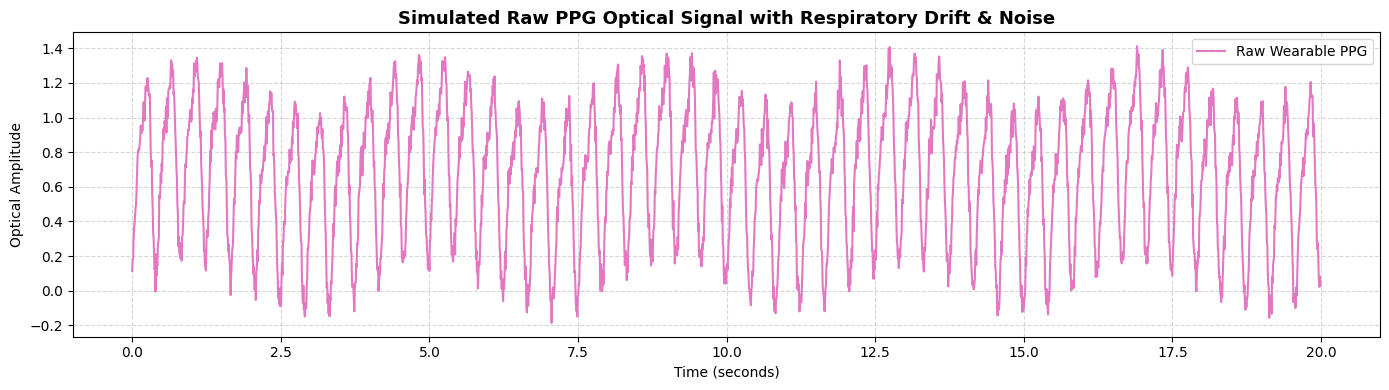

In [3]:
fs = 125.0  # Standard PPG wearable sampling rate (Hz)
duration_sec = 20.0
t = np.arange(0, duration_sec, 1.0 / fs)

# Synthetic pulse wave with heart rate ~ 72 bpm (1.2 Hz)
hr_freq = 1.2
systolic = np.sin(2 * np.pi * hr_freq * t) ** 2
dicrotic = 0.35 * np.sin(2 * np.pi * 2 * hr_freq * t + 0.5) ** 2
respiration = 0.15 * np.sin(2 * np.pi * 0.25 * t)  # 15 breaths/min (0.25 Hz)
noise = np.random.normal(0, 0.05, len(t))

ppg_raw = systolic + dicrotic + respiration + noise

plt.figure(figsize=(14, 4))
plt.plot(t, ppg_raw, color="#e377c2", lw=1.5, label="Raw Wearable PPG")
plt.title("Simulated Raw PPG Optical Signal with Respiratory Drift & Noise", fontsize=13, fontweight="bold")
plt.xlabel("Time (seconds)")
plt.ylabel("Optical Amplitude")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### 2. PPG Signal Filtering ($0.5 - 8.0\text{ Hz}$)

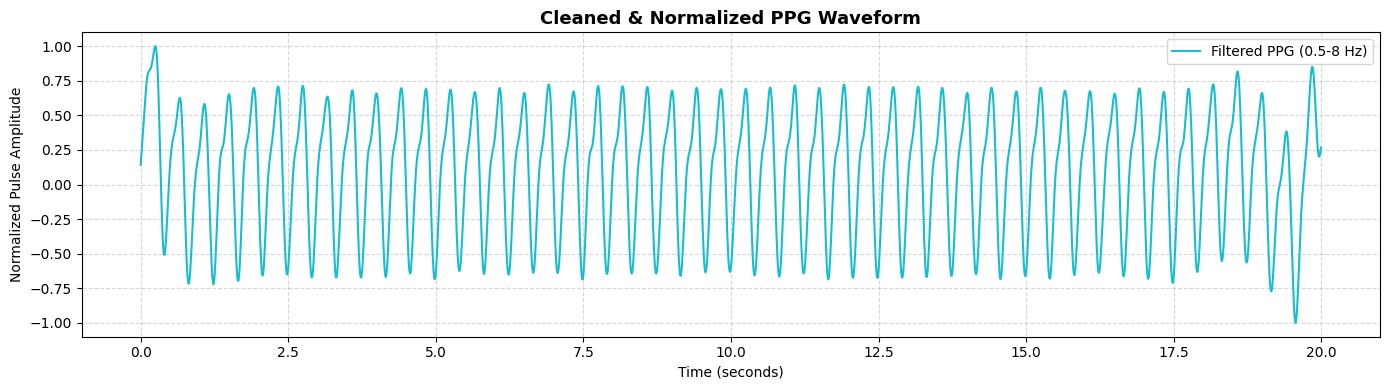

In [4]:
ppg_filtered = apply_bandpass_filter(ppg_raw, sampling_rate=fs, lowcut=0.5, highcut=8.0, order=3)
ppg_normalized = normalize_signal(ppg_filtered, method="min_max")

plt.figure(figsize=(14, 4))
plt.plot(t, ppg_normalized, color="#17becf", lw=1.5, label="Filtered PPG (0.5-8 Hz)")
plt.title("Cleaned & Normalized PPG Waveform", fontsize=13, fontweight="bold")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Pulse Amplitude")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### 3. Systolic Peak Detection & Pulse Intervals (PPI)

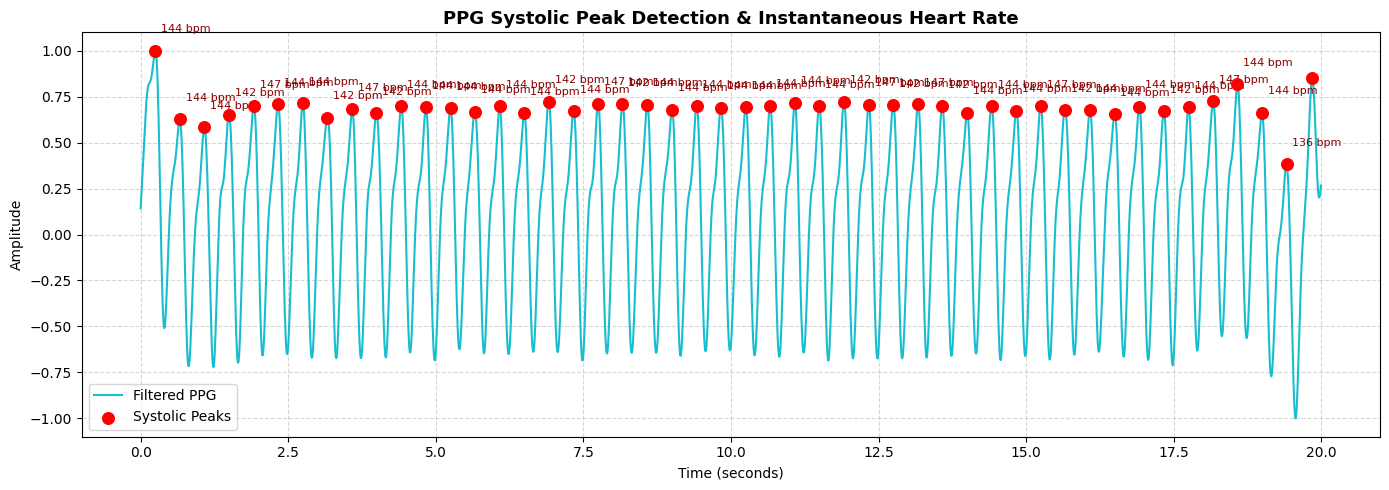

In [5]:
# Find systolic peaks
min_peak_distance = int(0.4 * fs)  # Max heart rate 150 bpm -> min 0.4s between peaks
peaks, _ = signal.find_peaks(ppg_normalized, distance=min_peak_distance, prominence=0.4)

peak_times = t[peaks]
peak_vals = ppg_normalized[peaks]

# Compute pulse intervals (in milliseconds)
ppi_ms = np.diff(peak_times) * 1000.0
heart_rate_bpm = 60.0 / (np.diff(peak_times))

plt.figure(figsize=(14, 5))
plt.plot(t, ppg_normalized, color="#17becf", lw=1.5, label="Filtered PPG")
plt.scatter(peak_times, peak_vals, color="red", s=70, zorder=5, label="Systolic Peaks")

for i, p_t in enumerate(peak_times[:-1]):
    plt.annotate(f"{heart_rate_bpm[i]:.0f} bpm", (p_t + 0.1, peak_vals[i] + 0.1), fontsize=8, color="darkred")

plt.title("PPG Systolic Peak Detection & Instantaneous Heart Rate", fontsize=13, fontweight="bold")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 4. Pulse Rate Variability (PRV) Metric Extraction

In [6]:
# Time-domain PRV metrics
mean_hr = np.mean(heart_rate_bpm)
sdnn = np.std(ppi_ms)
rmssd = np.sqrt(np.mean(np.diff(ppi_ms) ** 2))
pnn50 = (np.sum(np.abs(np.diff(ppi_ms)) > 50.0) / len(ppi_ms)) * 100.0

print("=" * 45)
print("     CLINICAL PULSE RATE VARIABILITY (PRV)   ")
print("=" * 45)
print(f"Mean Heart Rate (HR):   {mean_hr:.1f} BPM")
print(f"Mean Pulse Interval:    {np.mean(ppi_ms):.1f} ms")
print(f"SDNN (Overall HRV):     {sdnn:.2f} ms")
print(f"RMSSD (Parasympathetic):{rmssd:.2f} ms")
print(f"pNN50:                  {pnn50:.1f} %")
print("=" * 45)

     CLINICAL PULSE RATE VARIABILITY (PRV)   
Mean Heart Rate (HR):   143.9 BPM
Mean Pulse Interval:    417.0 ms
SDNN (Overall HRV):     5.86 ms
RMSSD (Parasympathetic):9.21 ms
pNN50:                  0.0 %
